# 04 · Redes neuronales convolucionales

Un MLP trata su entrada como una lista plana de números. Una imagen no es una lista plana: los píxeles tienen **vecinos**, y un patrón (un borde, el bucle de un "6") significa lo mismo aparezca donde aparezca. Una **red neuronal convolucional** incorpora ambos hechos en su estructura. Esa suposición incorporada se llama **sesgo inductivo**, y elegir el adecuado suele valer más que añadir parámetros.

Lo que vas a construir y medir en este notebook:

| Sección | Idea | Experimento |
|---|---|---|
| 1-4 | convolución, pesos compartidos, mapas de características | una pequeña CNN frente a un MLP con dígitos manuscritos, robustez ante imágenes desplazadas |
| 5 | aumento de datos | enseñar a la red que un dígito desplazado sigue siendo el mismo dígito |
| 6 | conexiones residuales | una CNN simple de 20 capas que no logra aprender frente a la misma profundidad con conexiones de salto |
| 7 | aprendizaje por transferencia | aprender los dígitos 5-9 con un puñado de ejemplos reutilizando una red entrenada con 0-4 |
| 8 | convoluciones eficientes | convoluciones 1×1 y separables en profundidad: una fracción de los parámetros a cambio de un pequeño coste en exactitud |

Todo usa **PyTorch** (el notebook 02 mostró lo que hace `loss.backward()` por dentro) y los trucos de entrenamiento del notebook 03. Se ejecuta en una CPU en pocos minutos y sin descargas: los dígitos vienen incluidos en scikit-learn.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0); np.random.seed(0); random.seed(0)
torch.set_num_threads(max(1, torch.get_num_threads()))
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())

## 1. ¿Por qué no un MLP?

Una imagen RGB de 224×224 tiene 150.528 entradas. Una sola capa densa de 1.000 neuronas necesitaría 150 millones de pesos, y tendría que aprender "oreja de gato arriba a la izquierda" y "oreja de gato abajo a la derecha" **por separado**.

Una **convolución** desliza un pequeño núcleo (kernel, p. ej. de 3×3) sobre la imagen y calcula una suma ponderada en cada posición:

$$ (I * K)[i,j] = \sum_{u}\sum_{v} I[i+u,\, j+v]\; K[u,v] $$

* **Conectividad local:** cada salida solo mira un pequeño parche.
* **Pesos compartidos:** se usa el mismo núcleo en todas partes, así que un detector de características aprendido una vez funciona en cualquier posición. Un núcleo de 3×3 tiene 9 pesos sea cual sea el tamaño de la imagen.
* **Apilar** convoluciones amplía el **campo receptivo**: la capa 1 ve bordes, la capa 2 esquinas y texturas, y las capas más profundas partes de objetos y objetos completos.

## 2. La convolución desde cero

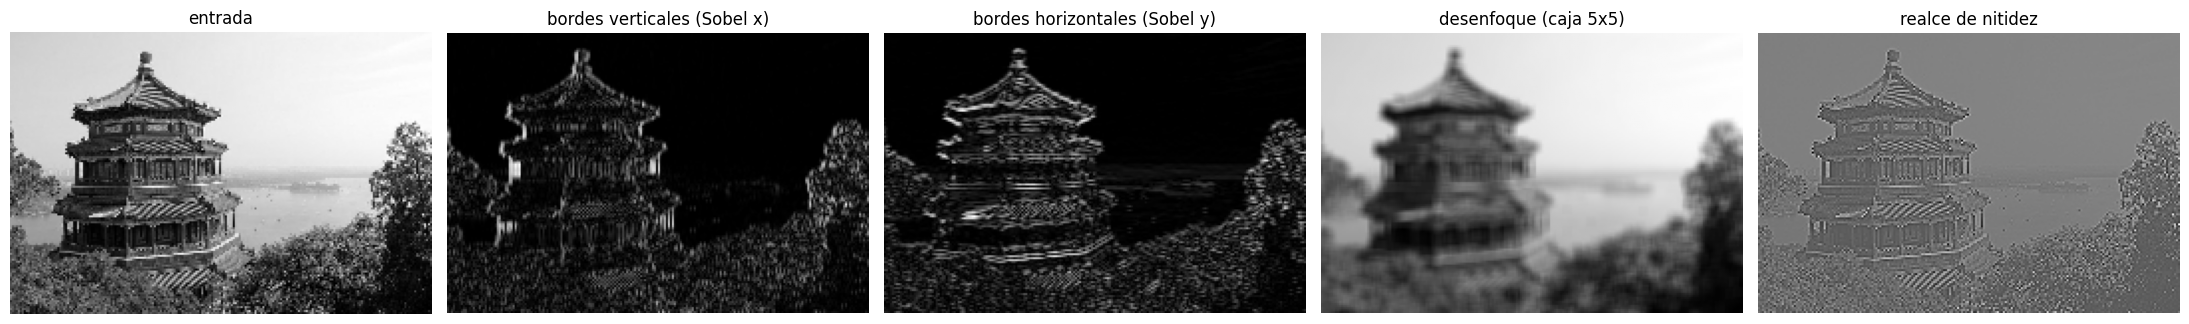

In [2]:
from sklearn.datasets import load_sample_image

def conv2d(img, kernel):
    kh, kw = kernel.shape
    H, W = img.shape
    out = np.zeros((H - kh + 1, W - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = (img[i:i + kh, j:j + kw] * kernel).sum()
    return out

img = load_sample_image("china.jpg").mean(axis=2)[::3, ::3] / 255.0   # escala de grises, con resolución reducida
kernels = {
    "bordes verticales (Sobel x)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "bordes horizontales (Sobel y)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "desenfoque (caja 5x5)": np.ones((5, 5)) / 25,
    "realce de nitidez": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
}
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("entrada")
for ax, (name, k) in zip(axes[1:], kernels.items()):
    out = conv2d(img, k)
    ax.imshow(np.abs(out) if "bordes" in name else out, cmap="gray"); ax.set_title(name)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

En una CNN estos núcleos **no se diseñan a mano**: son pesos aprendidos con retropropagación. Otros bloques de construcción:

* **Canales:** una capa convolucional tiene muchos núcleos, y cada uno produce un *mapa de características*. Una entrada RGB tiene 3 canales; una capa con 32 núcleos produce 32 canales.
* El **relleno** (padding) conserva el tamaño espacial; un **paso** (stride) mayor que 1 reduce la resolución.
* El **pooling** (p. ej. máximo de 2×2) reduce la resolución a la mitad, da cierta invariancia ante pequeños desplazamientos y ahorra cálculo.
* Al final, los mapas de características se aplanan (o se promedian globalmente) y entran en un pequeño clasificador MLP.

```
imagen 1×8×8 ─► Conv3×3(16) ─► ReLU ─► Conv3×3(32) ─► ReLU ─► MaxPool2 ─► 32×4×4 ─► aplanar ─► Lineal(64) ─► ReLU ─► Lineal(10) ─► clase
```

## 3. Entrenar una CNN con dígitos manuscritos

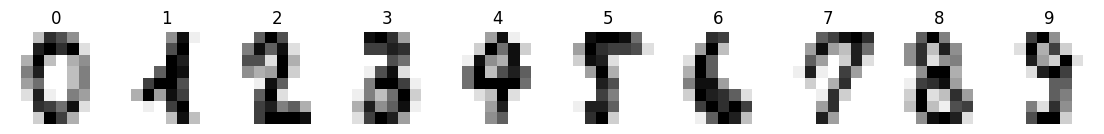

entrenamiento (1347, 1, 8, 8) prueba (450, 1, 8, 8)


In [3]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()                                 # 1.797 imágenes de 8x8 píxeles, valores de 0 a 16
Xd = torch.tensor(digits.images / 16.0, dtype=torch.float32).unsqueeze(1)   # (N, 1, 8, 8)
yd = torch.tensor(digits.target)
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.25, random_state=0, stratify=yd)

fig, axes = plt.subplots(1, 10, figsize=(14, 1.8))
for d, ax in enumerate(axes):
    ax.imshow(Xtr[ytr == d][0, 0], cmap="gray_r"); ax.set_title(str(d)); ax.axis("off")
plt.show()
print("entrenamiento", tuple(Xtr.shape), "prueba", tuple(Xte.shape))

ambos entrenados en 8.3 s
CNN  parámetros  38282  exactitud en prueba 98.9%
MLP  parámetros   9610  exactitud en prueba 98.0%


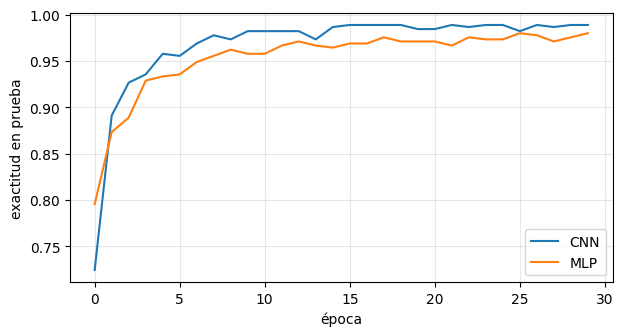

In [4]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(32 * 4 * 4, 64)
        self.fc2 = nn.Linear(64, 10)
    def features(self, x):
        a1 = F.relu(self.conv1(x))
        a2 = F.relu(self.conv2(a1))
        return a1, a2
    def forward(self, x):
        _, a2 = self.features(x)
        h = F.max_pool2d(a2, 2).flatten(1)
        return self.fc2(F.relu(self.fc1(h)))

class MLPBaseline(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x):
        return self.net(x)

def fit_classifier(model, epochs=30, lr=3e-3, batch=64):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch):
            b = perm[i:i + batch]
            loss = F.cross_entropy(model(Xtr[b]), ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            hist.append((model(Xte).argmax(1) == yte).float().mean().item())
    return hist

torch.manual_seed(0)
cnn, mlp = SmallCNN(), MLPBaseline()
t0 = time.time()
h_cnn, h_mlp = fit_classifier(cnn), fit_classifier(mlp)
print(f"ambos entrenados en {time.time() - t0:.1f} s")
print(f"CNN  parámetros {count_params(cnn):6d}  exactitud en prueba {h_cnn[-1]:.1%}")
print(f"MLP  parámetros {count_params(mlp):6d}  exactitud en prueba {h_mlp[-1]:.1%}")
plt.figure(figsize=(7, 3.5)); plt.plot(h_cnn, label="CNN"); plt.plot(h_mlp, label="MLP")
plt.xlabel("época"); plt.ylabel("exactitud en prueba"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### ¿Ayuda el sesgo convolucional? Desplacemos las imágenes de prueba un píxel

Ambos modelos se entrenaron con dígitos centrados. Desplaza cada imagen de prueba un píxel a la derecha: el MLP ve posiciones de entrada en su mayoría distintas, mientras que los núcleos compartidos de la CNN siguen encontrando los mismos trazos.

In [5]:
def shifted(x, dx):
    return torch.roll(x, shifts=dx, dims=3)

with torch.no_grad():
    for dx in [0, 1, 2]:
        acc_c = (cnn(shifted(Xte, dx)).argmax(1) == yte).float().mean().item()
        acc_m = (mlp(shifted(Xte, dx)).argmax(1) == yte).float().mean().item()
        print(f"desplazamiento {dx}px  CNN {acc_c:.1%}   MLP {acc_m:.1%}")

desplazamiento 0px  CNN 98.9%   MLP 98.0%
desplazamiento 1px  CNN 61.8%   MLP 45.6%
desplazamiento 2px  CNN 22.0%   MLP 17.8%


## 4. Mirar dentro: filtros aprendidos y mapas de características

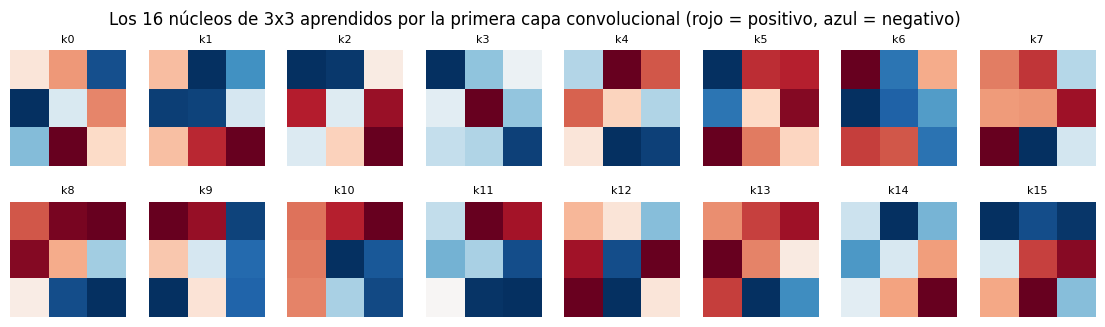

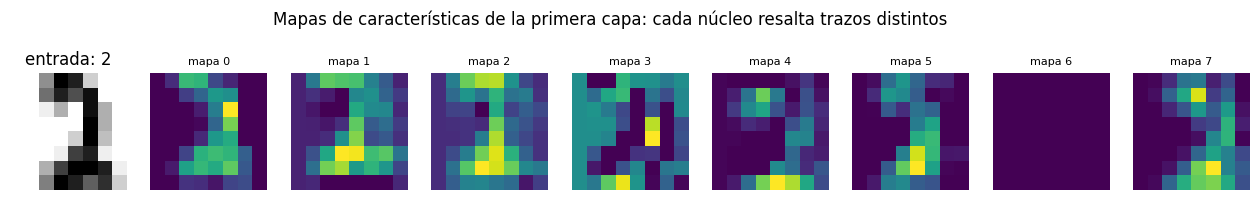

In [6]:
fig, axes = plt.subplots(2, 8, figsize=(14, 3.6))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(cnn.conv1.weight[k, 0].detach(), cmap="RdBu_r"); ax.axis("off"); ax.set_title(f"k{k}", fontsize=8)
fig.suptitle("Los 16 núcleos de 3x3 aprendidos por la primera capa convolucional (rojo = positivo, azul = negativo)"); plt.show()

sample = Xte[:1]
with torch.no_grad():
    a1, a2 = cnn.features(sample)
fig, axes = plt.subplots(1, 9, figsize=(16, 2.2))
axes[0].imshow(sample[0, 0], cmap="gray_r"); axes[0].set_title(f"entrada: {yte[0].item()}")
for k, ax in enumerate(axes[1:]):
    ax.imshow(a1[0, k], cmap="viridis"); ax.set_title(f"mapa {k}", fontsize=8)
for ax in axes: ax.axis("off")
plt.suptitle("Mapas de características de la primera capa: cada núcleo resalta trazos distintos", y=1.05); plt.show()

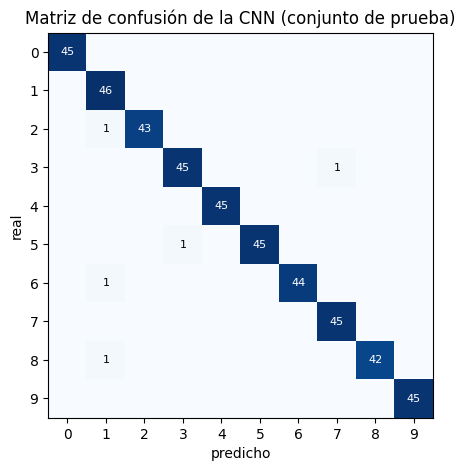

5 errores de 450


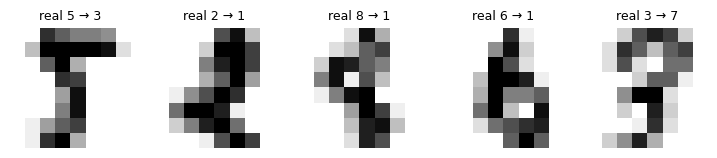

In [7]:
from sklearn.metrics import confusion_matrix
with torch.no_grad():
    pred = cnn(Xte).argmax(1)
cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 20 else "black")
ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.set_title("Matriz de confusión de la CNN (conjunto de prueba)")
ax.set_xticks(range(10)); ax.set_yticks(range(10)); plt.show()

wrong = (pred != yte).nonzero().ravel()
print(f"{len(wrong)} errores de {len(yte)}")
if len(wrong):
    fig, axes = plt.subplots(1, min(8, len(wrong)), figsize=(1.8 * min(8, len(wrong)), 2), squeeze=False)
    for ax, i in zip(axes[0], wrong[:8]):
        ax.imshow(Xte[i, 0], cmap="gray_r"); ax.axis("off"); ax.set_title(f"real {yte[i].item()} → {pred[i].item()}", fontsize=9)
    plt.show()

## 5. Aumento de datos: enseñar invariancias con datos falsos

La prueba de desplazamiento de arriba mostró que la CNN es *más* robusta que el MLP ante dígitos movidos, pero no inmune: la capa densa final sigue fijándose en las posiciones exactas. La solución más barata es **mostrarle a la red dígitos desplazados durante el entrenamiento**. Cada minilote se traslada al azar hasta 2 píxeles antes de la pasada hacia adelante, así que cada época ve imágenes ligeramente distintas.

El aumento de datos codifica un conocimiento que ya tienes ("un 3 desplazado sigue siendo un 3") como datos en lugar de como arquitectura. En la práctica es uno de los regularizadores más eficaces en visión: recortes aleatorios, volteos, variaciones de color, rotaciones. La única regla es que la transformación no debe cambiar la etiqueta (¡voltear un "6" verticalmente da un "9"!).

In [8]:
def random_shift(x, max_shift=2):
    # traslada cada imagen por separado y rellena con ceros el borde descubierto
    out = torch.zeros_like(x)
    for i in range(len(x)):
        dx, dy = np.random.randint(-max_shift, max_shift + 1, size=2)
        src = x[i, :, max(0, -dy):8 - max(0, dy), max(0, -dx):8 - max(0, dx)]
        out[i, :, max(0, dy):max(0, dy) + src.shape[1], max(0, dx):max(0, dx) + src.shape[2]] = src
    return out

def fit(model, X, y, Xv, yv, epochs=30, lr=3e-3, batch=64, augment=None, params=None):
    opt = torch.optim.Adam(params if params is not None else model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X))
        for i in range(0, len(X), batch):
            b = perm[i:i + batch]
            xb = augment(X[b]) if augment else X[b]
            loss = F.cross_entropy(model(xb), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            hist.append((model(Xv).argmax(1) == yv).float().mean().item())
    return hist

def shifted_xy(x, dx, dy):
    # desplazamiento determinista rellenando con ceros (sin dar la vuelta), para la prueba
    out = torch.zeros_like(x)
    out[:, :, max(0, dy):8 + min(0, dy), max(0, dx):8 + min(0, dx)] = x[:, :, max(0, -dy):8 - max(0, dy), max(0, -dx):8 - max(0, dx)]
    return out

torch.manual_seed(0); np.random.seed(0)
cnn_aug = SmallCNN()
fit(cnn_aug, Xtr, ytr, Xte, yte, augment=random_shift)

print(f"{'prueba desplazada':24s} {'CNN simple':>10s} {'CNN aumentada':>14s}")
with torch.no_grad():
    for dx, dy in [(0, 0), (1, 0), (0, 1), (2, 0), (2, 2)]:
        xs = shifted_xy(Xte, dx, dy)
        a = (cnn(xs).argmax(1) == yte).float().mean().item()
        b = (cnn_aug(xs).argmax(1) == yte).float().mean().item()
        print(f"{f'({dx}, {dy}) px':24s} {a:10.1%} {b:14.1%}")

prueba desplazada        CNN simple  CNN aumentada
(0, 0) px                     98.9%          94.7%
(1, 0) px                     62.0%          95.3%
(0, 1) px                     53.1%          95.6%
(2, 0) px                     22.9%          91.1%
(2, 2) px                      2.2%          85.3%


La red aumentada cede unos pocos puntos con las imágenes originales, perfectamente centradas (ahora dedica capacidad a posiciones que rara vez verá en este conjunto de prueba), y gana muchísimo con las desplazadas. Nunca vio ni una sola imagen *real* adicional: todo el conocimiento extra vino de la regla de aumento.

## 6. Ir a lo profundo: por qué importan las conexiones residuales

Las redes más profundas pueden representar funciones más complejas, así que lo natural es apilar más capas. Hacia 2015 los investigadores notaron algo extraño: más allá de unas 20 capas, las redes profundas **simples** empeoraban, incluso en el conjunto de entrenamiento. Eso no es sobreajuste (notebook 03), es un fallo de optimización: el gradiente tiene que atravesar cada capa en su camino de vuelta, y por el camino se encoge o se desordena.

La solución propuesta en el artículo de ResNet (He et al., 2015) es casi vergonzosamente simple. En lugar de pedirle a un bloque que calcule una representación nueva $H(x)$, se le pide una *corrección* de su entrada:

$$ y = x + F(x) $$

El camino identidad (la **conexión de salto**) le da al gradiente una autopista directa hacia las primeras capas: $\partial y / \partial x = I + \partial F / \partial x$, así que aunque $\partial F/\partial x$ sea diminuto, la señal sobrevive. Un bloque que no tenga nada útil que añadir puede aprender simplemente $F \approx 0$ y comportarse como la identidad, de modo que la profundidad extra ya no puede perjudicar. Volverás a encontrar la misma idea como el **flujo residual** del transformer (notebook 07).

Construimos dos redes de 20 convoluciones que se diferencian **solo** en las conexiones de salto y las entrenamos durante el mismo número de pasos.

simple, 20 capas conv.     parámetros 46,730  exactitud en prueba 9.8%  (43 s)


residual, 20 capas conv.   parámetros 46,730  exactitud en prueba 95.8%  (44 s)


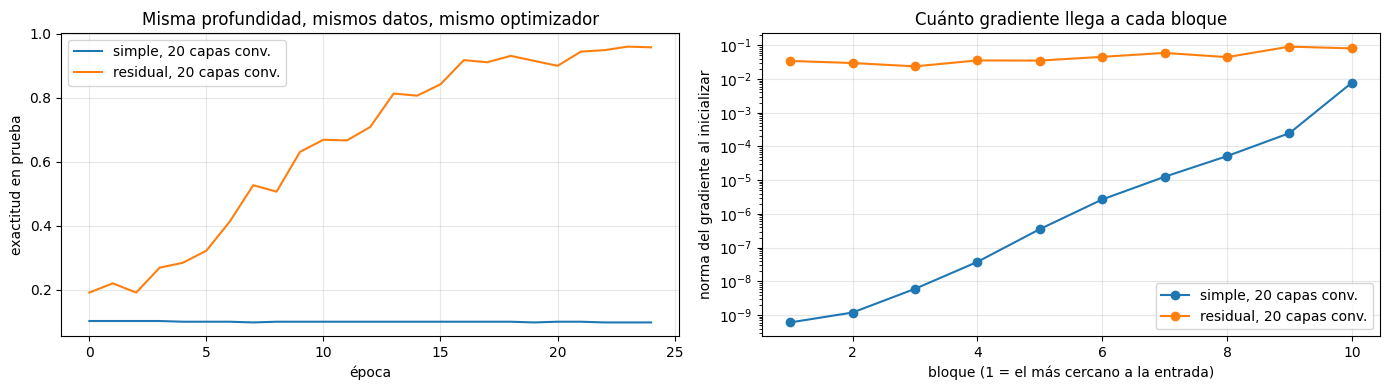

In [9]:
class ConvBlock(nn.Module):
    # dos convoluciones 3x3; con residual=True la entrada se vuelve a sumar a la salida
    def __init__(self, ch, residual):
        super().__init__()
        self.c1, self.c2 = nn.Conv2d(ch, ch, 3, padding=1), nn.Conv2d(ch, ch, 3, padding=1)
        self.residual = residual
    def forward(self, x):
        out = self.c2(F.relu(self.c1(x)))
        return F.relu(x + out if self.residual else out)

class DeepCNN(nn.Module):
    def __init__(self, n_blocks=10, ch=16, residual=False):
        super().__init__()
        self.stem = nn.Conv2d(1, ch, 3, padding=1)
        self.blocks = nn.Sequential(*[ConvBlock(ch, residual) for _ in range(n_blocks)])
        self.head = nn.Linear(ch, 10)
    def forward(self, x):
        h = self.blocks(F.relu(self.stem(x)))
        return self.head(h.mean(dim=(2, 3)))          # pooling de promedio global

def grad_norms(model):
    # tamaño del gradiente que llega a cada bloque para un lote, desde la salida (derecha) hasta la entrada (izquierda)
    model.zero_grad()
    F.cross_entropy(model(Xtr[:256]), ytr[:256]).backward()
    return [b.c1.weight.grad.norm().item() for b in model.blocks]

curves, grads = {}, {}
for name, res in [("simple, 20 capas conv.", False), ("residual, 20 capas conv.", True)]:
    torch.manual_seed(0)
    m = DeepCNN(residual=res)
    grads[name] = grad_norms(m)
    t0 = time.time()
    curves[name] = fit(m, Xtr, ytr, Xte, yte, epochs=25, lr=1e-3)
    print(f"{name:26s} parámetros {count_params(m):,}  exactitud en prueba {curves[name][-1]:.1%}  ({time.time() - t0:.0f} s)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name in curves:
    axes[0].plot(curves[name], label=name)
    axes[1].semilogy(range(1, 11), grads[name], marker="o", label=name)
axes[0].set_xlabel("época"); axes[0].set_ylabel("exactitud en prueba"); axes[0].legend(); axes[0].set_title("Misma profundidad, mismos datos, mismo optimizador")
axes[1].set_xlabel("bloque (1 = el más cercano a la entrada)"); axes[1].set_ylabel("norma del gradiente al inicializar")
axes[1].set_title("Cuánto gradiente llega a cada bloque"); axes[1].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

La gráfica de la derecha es el diagnóstico. En la red simple, el gradiente que llega a los primeros bloques es varios órdenes de magnitud menor que arriba, así que las primeras capas apenas se mueven y la red entrena lentamente o no entrena. Con conexiones de salto, cada bloque recibe un gradiente sano desde el principio.

La normalización por lotes (notebook 03) también ayuda a las redes profundas simples, y las ResNet reales usan ambas cosas. La conexión de salto es la pieza que hizo rutinarias las redes de más de 100 capas, y hoy está en casi todas las arquitecturas profundas.

## 7. Aprendizaje por transferencia: reutilizar lo que otra red ya aprendió

Los datos etiquetados son caros. Si una red ya aprendió características útiles en una tarea **relacionada** con muchos datos, podemos partir de esas características en lugar de pesos aleatorios. Así funciona casi toda la visión artificial práctica: se parte de una red preentrenada con millones de imágenes y se adapta a tus pocos cientos.

Para mantenerlo todo sin conexión, escenificamos la misma situación con dígitos:

* **Tarea de origen (muchos datos):** clasificar los dígitos del 0 al 4, usando todas sus imágenes de entrenamiento.
* **Tarea de destino (muy pocos datos):** clasificar los dígitos del 5 al 9, con solo $k$ imágenes etiquetadas por clase.

Los trazos, bucles y esquinas se comparten entre las dos mitades, así que las características aprendidas con 0-4 *deberían* ayudar con 5-9. Que de verdad lo hagan depende de cómo se entrenó la red de origen, así que la entrenamos dos veces: una de forma simple y otra con el aumento por desplazamiento aleatorio de la sección 5. Para cada red de origen comparamos tres estrategias:

| Estrategia | Qué se entrena en la tarea de destino |
|---|---|
| desde cero | todos los pesos, partiendo de valores aleatorios |
| características congeladas | solo una nueva cabeza clasificadora; las capas convolucionales conservan los pesos de origen |
| ajuste fino | todo, partiendo de los pesos de origen, con una tasa de aprendizaje pequeña |

origen simple     (dígitos 0-4): exactitud en prueba 99.1%


origen aumentado  (dígitos 0-4): exactitud en prueba 93.8%



125 entrenamientos en la tarea de destino en 167 s

tasa de error en los dígitos 5-9                 k=1     k=2     k=5    k=10    k=25
desde cero                                     28.8%   20.2%   10.3%    6.2%    2.3%
características congeladas, origen simple      27.5%   18.9%    7.9%    6.2%    3.2%
ajuste fino, origen simple                     26.2%   17.9%    8.6%    7.0%    3.4%
características congeladas, origen aumentado   26.7%   17.0%    5.8%    3.8%    1.9%
ajuste fino, origen aumentado                  27.9%   16.1%    7.1%    5.2%    2.3%


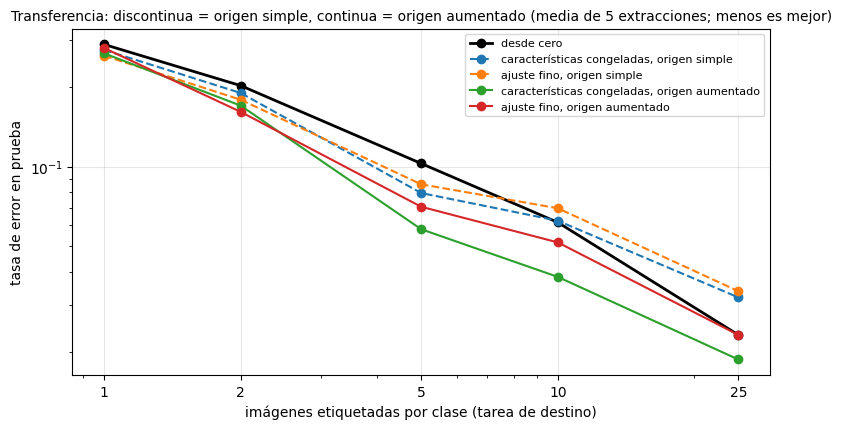

In [10]:
src_tr, src_te = ytr < 5, yte < 5
Xt_te, yt_te = Xte[yte >= 5], yte[yte >= 5] - 5

class SmallCNN5(SmallCNN):
    def __init__(self):
        super().__init__()
        self.fc2 = nn.Linear(64, 5)
    def new_head(self):
        # clasificador nuevo, inicializado al azar, sobre las características convolucionales
        self.fc1, self.fc2 = nn.Linear(32 * 4 * 4, 64), nn.Linear(64, 5)
        return list(self.fc1.parameters()) + list(self.fc2.parameters())

sources = {}
for name, aug in [("origen simple", None), ("origen aumentado", random_shift)]:
    torch.manual_seed(0); np.random.seed(0)
    net = SmallCNN5()
    h = fit(net, Xtr[src_tr], ytr[src_tr], Xte[src_te], yte[src_te], epochs=30, augment=aug)
    sources[name] = {k: v.clone() for k, v in net.state_dict().items()}
    print(f"{name:17s} (dígitos 0-4): exactitud en prueba {h[-1]:.1%}")

def few_shot_split(k, seed):
    g = np.random.default_rng(seed)
    idx = []
    for d in range(5, 10):
        pool = np.where((ytr == d).numpy())[0]
        idx += list(g.choice(pool, size=k, replace=False))
    idx = torch.tensor(idx)
    return Xtr[idx], ytr[idx] - 5

def run(strategy, k, seed, source=None):
    torch.manual_seed(seed)
    m = SmallCNN5()
    Xk, yk = few_shot_split(k, seed)
    if strategy == "desde cero":
        return fit(m, Xk, yk, Xt_te, yt_te, epochs=60, lr=3e-3, batch=16)[-1]
    m.load_state_dict(sources[source])
    head = m.new_head()                                   # la cabeza anterior solo conocía los dígitos 0-4
    if strategy == "características congeladas":
        for p in list(m.conv1.parameters()) + list(m.conv2.parameters()):
            p.requires_grad = False
        return fit(m, Xk, yk, Xt_te, yt_te, epochs=60, lr=3e-3, batch=16, params=head)[-1]
    return fit(m, Xk, yk, Xt_te, yt_te, epochs=60, lr=1e-3, batch=16)[-1]   # ajuste fino: tasa de aprendizaje menor

ks = [1, 2, 5, 10, 25]
runs = [("desde cero", None)] + [(s, src) for src in sources for s in ["características congeladas", "ajuste fino"]]
t0 = time.time()
results = {}
for s, src in runs:
    label = s if src is None else f"{s}, {src}"
    results[label] = [np.mean([run(s, k, seed, src) for seed in range(5)]) for k in ks]
print(f"\n{len(runs) * len(ks) * 5} entrenamientos en la tarea de destino en {time.time() - t0:.0f} s\n")

print(f"{'tasa de error en los dígitos 5-9':44s}" + "".join(f"{f'k={k}':>8s}" for k in ks))
for label, acc in results.items():
    print(f"{label:44s}" + "".join(f"{1 - a:8.1%}" for a in acc))
plt.figure(figsize=(9, 4.5))
for label, acc in results.items():
    style = dict(color="k", lw=2) if label == "desde cero" else dict(ls="--" if "simple" in label else "-")
    plt.plot(ks, [1 - a for a in acc], marker="o", label=label, **style)
plt.xscale("log"); plt.yscale("log"); plt.xticks(ks, ks); plt.xlabel("imágenes etiquetadas por clase (tarea de destino)"); plt.ylabel("tasa de error en prueba")
plt.title("Transferencia: discontinua = origen simple, continua = origen aumentado (media de 5 extracciones; menos es mejor)", fontsize=10)
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

Las líneas discontinuas son la parte incómoda del resultado. Las características de la red de origen **simple** ayudan un poco con uno a cinco ejemplos por clase, pero con 10 ejemplos ya no son mejores que entrenar desde cero, y con 25 son *peores*: están especializadas en los dígitos 0-4 exactos y centrados con los que se entrenaron, y partir de ellas estorba en cuanto la tarea de destino tiene suficientes datos propios. Las características congeladas de la red de origen **aumentada** superan a entrenar desde cero con cualquier cantidad de datos, y con 5 ejemplos por clase reducen el error aproximadamente a la mitad.

Fíjate en la sorpresa de las dos primeras líneas impresas: la red de origen aumentada es *peor* en su propia tarea (cedió exactitud con los dígitos de prueba perfectamente centrados, como en la sección 5) y, aun así, es el mejor punto de partida para una tarea nueva. Misma arquitectura, mismos datos de origen, misma tarea de destino: el aumento de datos obligó a la red de origen a aprender características que no dependen de una posición exacta, y las características generales son las que se transfieren. La puntuación de un modelo en su tarea original es una mala guía de lo útiles que serán sus características en otra.

Dos advertencias honestas más sobre este montaje de juguete:

* Una CNN con dígitos de 8×8 ya aprende muy bien desde cero (su sesgo inductivo hace mucho trabajo), así que incluso la mejora buena es moderada. Con fotos reales y una red preentrenada con millones de imágenes variadas, la diferencia suele ser mucho mayor.
* Los modelos preentrenados que se usan en la práctica se entrenan con mucho aumento de datos sobre conjuntos enormes y diversos, y por eso sus características se transfieren tan bien. "El aprendizaje por transferencia funciona" es, en realidad, una afirmación sobre *cómo se entrenó el modelo de origen*.

Reglas prácticas que se trasladan a proyectos reales:

* **Conjunto de destino diminuto, dominio parecido:** congela la red base y entrena solo una cabeza nueva.
* **Más datos de destino:** haz ajuste fino de todo con una tasa de aprendizaje varias veces menor que para entrenar desde cero, para que las características útiles se ajusten en lugar de sobrescribirse.
* **Dominio muy distinto** (por ejemplo, radiografías con una red preentrenada con fotos de vacaciones): las primeras capas (bordes, texturas) se siguen transfiriendo bien, las últimas no tanto.

## 8. Convoluciones eficientes: 1×1 y separables en profundidad

Una convolución estándar de $3\times3$ de $C_{in}$ a $C_{out}$ canales tiene $9\, C_{in} C_{out}$ pesos: cada canal de salida mira cada canal de entrada en cada desplazamiento espacial. Dos bloques más baratos se usan en todas las redes modernas (Inception, MobileNet, EfficientNet):

* **Convolución 1×1:** una pequeña capa densa aplicada en cada píxel. Mezcla canales pero no espacio, y es la forma estándar de reducir o aumentar el número de canales a bajo coste.
* **Convolución separable en profundidad:** divide el trabajo en dos. Primero una convolución *en profundidad* de $3\times3$ filtra cada canal por separado ($9\, C_{in}$ pesos) y después una convolución *puntual* de $1\times1$ mezcla los canales ($C_{in} C_{out}$ pesos). Con $C_{in} = C_{out} = 64$ eso supone unas 8 veces menos pesos y operaciones.

In [11]:
def sep_conv(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cin, 3, padding=1, groups=cin),   # en profundidad: un filtro 3x3 por canal
                         nn.Conv2d(cin, cout, 1))                         # puntual: mezcla los canales

for cin, cout in [(16, 32), (64, 64), (256, 256)]:
    std, sep = nn.Conv2d(cin, cout, 3, padding=1), sep_conv(cin, cout)
    print(f"{cin:3d} -> {cout:3d} canales   3x3 estándar: {count_params(std):7,d} parámetros   "
          f"separable en profundidad: {count_params(sep):6,d}   proporción {count_params(std) / count_params(sep):.1f}x")

class SmallSepCNN(SmallCNN):
    # idéntica a SmallCNN salvo que la segunda convolución es separable en profundidad
    def __init__(self):
        super().__init__()
        self.conv2 = sep_conv(16, 32)

torch.manual_seed(0)
sep_net = SmallSepCNN()
h_sep = fit(sep_net, Xtr, ytr, Xte, yte)
conv_params = lambda m: sum(p.numel() for n, p in m.named_parameters() if n.startswith("conv"))
print(f"\nCNN estándar    parámetros conv. {conv_params(cnn):5d}   exactitud en prueba {h_cnn[-1]:.1%}")
print(f"CNN separable   parámetros conv. {conv_params(sep_net):5d}   exactitud en prueba {h_sep[-1]:.1%}")

 16 ->  32 canales   3x3 estándar:   4,640 parámetros   separable en profundidad:    704   proporción 6.6x
 64 ->  64 canales   3x3 estándar:  36,928 parámetros   separable en profundidad:  4,800   proporción 7.7x
256 -> 256 canales   3x3 estándar: 590,080 parámetros   separable en profundidad: 68,352   proporción 8.6x



CNN estándar    parámetros conv.  4800   exactitud en prueba 98.9%
CNN separable   parámetros conv.   864   exactitud en prueba 96.7%


La red separable usa varias veces menos pesos de convolución a cambio de una pequeña caída en exactitud. Con el número de canales de las redes reales, el ahorro se acerca a un orden de magnitud, y eso es buena parte de lo que permite que las redes neuronales sean lo bastante rápidas para ejecutarse en un teléfono. Arquitecturas como MobileNet recuperan después la exactitud invirtiendo el ahorro en más canales o capas.

**Hacia dónde fueron después las CNN:** LeNet (1998) → AlexNet (2012, el gran avance del aprendizaje profundo en ImageNet) → VGG → **ResNet** (2015, conexiones residuales) → MobileNet / EfficientNet (bloques eficientes, escalado cuidadoso) → los transformers de visión, que sustituyen las convoluciones por atención sobre parches de imagen (notebook 07). El notebook 09 lleva las CNN más allá de "una etiqueta por imagen": segmentación, detección y similitud aprendida.

## Ideas clave

* Una convolución es un pequeño filtro que se desliza sobre la imagen. Los **pesos compartidos** hacen que las CNN sean eficientes con los datos y robustas a la posición de un patrón.
* El **aumento de datos** enseña gratis invariancias que ya conoces.
* Las **conexiones residuales** ($y = x + F(x)$) mantienen vivos los gradientes a lo largo de la profundidad, y eso es lo que hizo entrenables las redes muy profundas.
* El **aprendizaje por transferencia** reutiliza características de una tarea con muchos datos, y gana más cuando tus propios datos etiquetados escasean.
* Las convoluciones **1×1 y separables en profundidad** reducen parámetros y cálculo en grandes factores a cambio de una pequeña pérdida de exactitud.

## Ejercicios

1. Añade `nn.BatchNorm2d` después de cada convolución en la red *simple* de 20 capas (sección 6). ¿Cuánta parte de la diferencia con la red residual cierra?
2. Aumenta la profundidad a 40 convoluciones (`n_blocks=20`). ¿Qué le pasa a cada red?
3. En la sección 5, añade rotaciones aleatorias de ±15° como aumento de datos (pista: `torch.rot90` solo gira 90°; prueba `torch.nn.functional.affine_grid`). ¿Ayuda con el conjunto de prueba original, sin desplazar?
4. Transfiere en la otra dirección: preentrena con 5-9 y adapta a 0-4. ¿Es simétrico el beneficio?
5. Entrena la red de origen con los dígitos 0-4 durante 5 épocas en lugar de 30 (con aumento de datos). ¿Las características de origen poco entrenadas se transfieren mejor o peor que las completamente entrenadas?
6. Haz ajuste fino con una tasa de aprendizaje de 1e-2. ¿Qué pasa con 2 ejemplos por clase, y por qué?